# Introduction 
* Data Collection: Gather customer data, which can include demographic information, purchase history, website activity, and more.

* Data Preprocessing: Prepare and clean the data by handling missing values, scaling numerical features, and encoding categorical variables.
* Feature Selection/Engineering: Choose relevant features for clustering or create new features that capture customer behavior.
* Clustering: Apply K-Means clustering to segment customers into distinct groups based on their behavior or characteristics.
* Interpretation: Analyze the characteristics of each cluster to understand the customer segments better.
* Targeted Marketing: Tailor marketing strategies and promotions to each customer segment to improve engagement and conversion.

In [2]:
# Import Libraries

In [15]:
import pandas as pd
import numpy as np 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [16]:
data = pd.read_csv('Mall_Customers.csv')
data.head(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [17]:
# Select relevant features 
data.drop('CustomerID', axis = 1)

selected_features = ['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
data = data[selected_features]
data.fillna(0, inplace=True)

data.head(5)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [21]:
## Encoding 
data['Gender'] = data['Gender'].astype('category')
data['Gender'] = data['Gender'].cat.codes

In [22]:
# Set Scaler

In [23]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

In [24]:
num_clusters = 3

In [27]:
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(scaled_data)

data['Cluster'] = cluster_labels
data.head(5)

,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,19,15,39,0
1,1,21,15,81,0
2,0,20,16,6,1
3,0,23,16,77,0
4,0,31,17,40,1


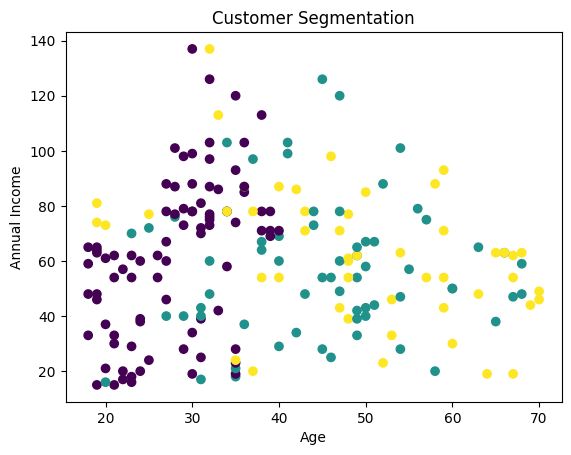

In [28]:
# Visualize KMeans
plt.scatter(data['Age'], data['Annual Income (k$)'], c=cluster_labels)
plt.xlabel('Age')
plt.ylabel('Annual Income')
plt.title('Customer Segmentation')
plt.show()
